# 02 · Attacks, timeouts and the retry storm

A retransmitted packet is extra load. When attacks or timeouts make attempts fail, the
retries raise the load, which raises queueing delay, which causes more timeouts. This
notebook shows when that feedback loop settles and when it runs away.

We use Case 2 (post-service modification: the packet is served, then rejected) with
service rate `μ = 10` and timeout `T = 1`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aqnet

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("aqnet", aqnet.__version__)

aqnet 0.3.0


## The conservation curve Γ(Λ)

Let `Λ` be the attempt rate the server sees (fresh packets plus retries). Only a fraction
`P_succ(Λ)` of attempts succeed, so the useful throughput is `Γ(Λ) = Λ · P_succ(Λ)`.
In steady state that must equal the fresh arrival rate `λ`.

`Γ` rises and then falls: past a point, more attempts mean so much queueing that most of
them time out. The peak is the most fresh traffic the system can carry, `λ_crit`.

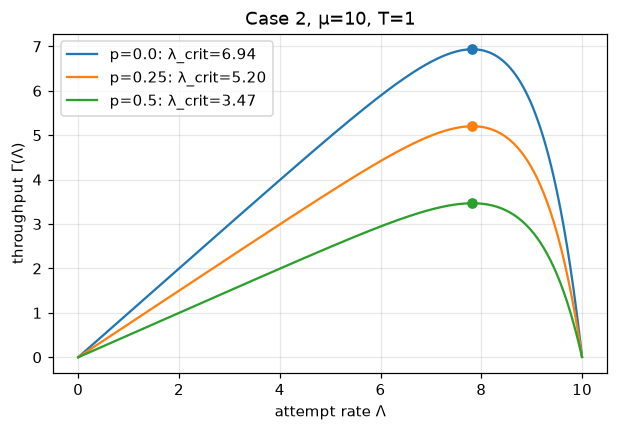

In [2]:
mu, T = 10.0, 1.0
Lam = np.linspace(1e-3, mu * 0.9999, 600)
fig, ax = plt.subplots(figsize=(6.5, 4))
for p in (0.0, 0.25, 0.5):
    g = [aqnet.throughput_curve_gamma(x, "one_node_modification", p, mu, T) for x in Lam]
    sn = aqnet.solve_saddle_node_bifurcation("one_node_modification", p=p, mu=mu, T=T)
    line, = ax.plot(Lam, g, label=f"p={p}: λ_crit={sn.lambda_crit_sn:.2f}")
    ax.plot(sn.Lambda_sn, sn.lambda_crit_sn, "o", color=line.get_color())
ax.set(xlabel="attempt rate Λ", ylabel="throughput Γ(Λ)", title="Case 2, μ=10, T=1")
ax.legend()
plt.show()

## Timeouts cost capacity even without an attacker

Even at `p = 0`, a short timeout makes slow attempts count as failures. The table compares
`λ_crit` with the naive capacity `μ(1 - p)` that ignores timeouts.

In [3]:
print(f"{'μT':>6}{'λ_crit/μ':>11}{'fraction of naive capacity':>30}")
for muT in (0.5, 1, 2, 5, 10, 50):
    sn = aqnet.solve_saddle_node_bifurcation("one_node_modification", p=0.0, mu=10.0, T=muT / 10.0)
    print(f"{muT:>6}{sn.lambda_crit_sn / 10.0:>11.3f}{sn.capacity_ratio_vs_naive:>30.1%}")

    μT   λ_crit/μ    fraction of naive capacity
   0.5      0.111                         11.1%
     1      0.199                         19.9%
     2      0.330                         33.0%
     5      0.544                         54.4%
    10      0.694                         69.4%
    50      0.903                         90.3%


## Retry amplification near the limit

On the stable branch, each fresh packet costs `Λ/λ` attempts. Far from the limit that is
just `1/(1 − p)`, the attack overhead; near `λ_crit` timeouts add more retries on top, and
the curve turns vertical at the fold (the square-root law of notebook 03). Mean delay
roughly quadruples across the range.

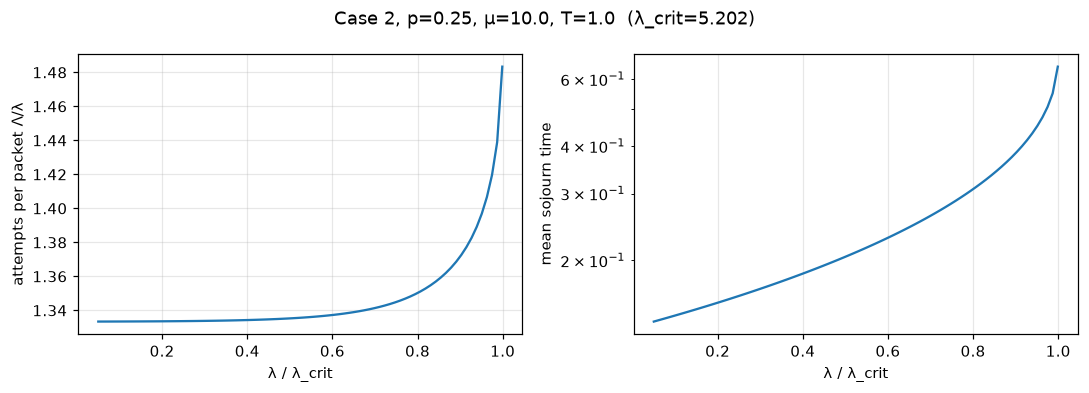

In [4]:
p = 0.25
sn = aqnet.solve_saddle_node_bifurcation("one_node_modification", p=p, mu=mu, T=T)
fr = np.linspace(0.05, 0.999, 80)
amp, delay = [], []
for f in fr:
    d = aqnet.solve_dual_fixed_points(f * sn.lambda_crit_sn, "one_node_modification", p=p, mu=mu, T=T)
    amp.append(d.Lambda_stable / d.lambda_ext)
    delay.append(d.expected_total_time_stable)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(fr, amp); a1.set(xlabel="λ / λ_crit", ylabel="attempts per packet Λ/λ")
a2.plot(fr, delay); a2.set(xlabel="λ / λ_crit", ylabel="mean sojourn time", yscale="log")
fig.suptitle(f"Case 2, p={p}, μ={mu}, T={T}  (λ_crit={sn.lambda_crit_sn:.3f})")
plt.tight_layout(); plt.show()

## The retry storm in simulation

Below `λ_crit` there are **two** fixed points: a stable one and an unstable one above it
(the separatrix). A queue sitting at the stable point recovers from small disturbances,
but a burst that pushes the in-flight retry population past the separatrix never comes
back: retries keep feeding more timeouts until the in-flight population hits the cap.

Four SimPy runs at `λ = 3` (well below `λ_crit ≈ 5.2`) and one above the limit:

In [5]:
runs = [
    ("steady λ=3", dict(lambda_ext=3.0)),
    ("λ=3, 3× burst for 3 s", dict(lambda_ext=3.0, burst_factor=3.0, burst_duration=3.0)),
    ("λ=3, 3× burst for 8 s", dict(lambda_ext=3.0, burst_factor=3.0, burst_duration=8.0)),
    ("steady λ=4.5", dict(lambda_ext=4.5)),
    ("steady λ=5.5 (> λ_crit)", dict(lambda_ext=5.5)),
]
print(f"{'scenario':<26}{'collapsed':>10}{'peak in-flight':>16}{'sim Λ':>8}{'theory Λ_stable':>17}")
for name, kw in runs:
    r = aqnet.simulate_metastable_retry_collapse_simpy(p=p, mu=mu, T=T, sim_time=240.0, seed=7, **kw)
    print(f"{name:<26}{str(r['collapse_triggered']):>10}{r['peak_inflight']:>16}"
          f"{r['sim_attempt_rate_mean']:>8.2f}{r['Lambda_stable_theory']:>17.2f}")

scenario                   collapsed  peak in-flight   sim Λ  theory Λ_stable
steady λ=3                     False               7    4.08             4.01
λ=3, 3× burst for 3 s          False              12    4.14             4.01
λ=3, 3× burst for 8 s           True             251   10.98             4.01
steady λ=4.5                   False               9    5.96             6.13
steady λ=5.5 (> λ_crit)         True             251   10.35              nan


Same burst height, different outcome: for this seed the 3-second burst is absorbed and the
8-second one tips the queue over. Whether a given burst crosses the separatrix is random,
so the next cell sweeps burst length over 24 seeds to estimate the collapse probability.

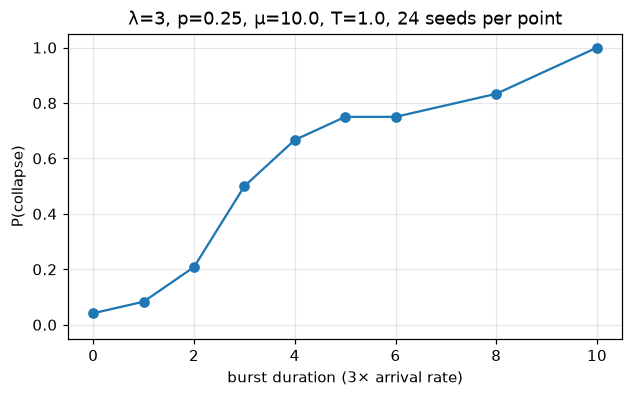

{0.0: 0.042, 1.0: 0.083, 2.0: 0.208, 3.0: 0.5, 4.0: 0.667, 5.0: 0.75, 6.0: 0.75, 8.0: 0.833, 10.0: 1.0}


In [6]:
durations = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0]
seeds = range(24)
prob = []
for dur in durations:
    hits = sum(
        aqnet.simulate_metastable_retry_collapse_simpy(
            lambda_ext=3.0, p=p, mu=mu, T=T, burst_factor=3.0, burst_duration=dur,
            sim_time=120.0, seed=s,
        )["collapse_triggered"]
        for s in seeds
    )
    prob.append(hits / len(seeds))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(durations, prob, marker="o")
ax.set(xlabel="burst duration (3× arrival rate)", ylabel="P(collapse)", ylim=(-0.05, 1.05),
       title=f"λ=3, p={p}, μ={mu}, T={T}, {len(seeds)} seeds per point")
plt.show()
print({d: round(pr, 3) for d, pr in zip(durations, prob)})

Collapse probability climbs from near zero to one as the burst gets longer. Note that even
with no burst a run occasionally collapses: in a finite stochastic queue the lower branch
is only *metastable*, and a large enough random excursion can cross the separatrix on its
own. The closer `λ` is to `λ_crit`, the narrower the gap and the more often that happens.